# FD001: sensor thay đổi bao nhiêu từ đầu đến cuối đời?

**Học viên:** Phan Nguyễn Mai Phương — **MSHV:** 25002711

Notebook 01 cho thấy sensor 11 thường tăng khi động cơ gần hỏng. Ở đây, câu hỏi là:
**mức tăng đó có nhất quán trên 100 động cơ train không?**

Bắt đầu từ sensor 11 của động cơ train 1: lấy trung bình cycle 163–192 trừ trung bình cycle 1–30.
Sau đó làm tương tự cho mọi động cơ và sensor, tính khoảng tin cậy rồi kiểm định.
Các bảng được tính lại từ raw train; test không được đọc. Kết quả mới nằm trong `outputs/notebook02/run-*/`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "src/cmapss").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
RAW_PATH = ROOT / "data/raw/train_FD001.txt"
from cmapss.presentation import COLORS, apply_plot_style, style_figure
apply_plot_style()


## 1. Từ hai đoạn thời gian đến một chênh lệch

Với động cơ train 1, tuổi thọ train là 192 cycle. Hai đoạn đầu/cuối đều dài 30 cycle và không chồng nhau.
Gọi $\Delta_i$ là trung bình cuối đời trừ trung bình đầu đời của động cơ $i$.
Giá trị dương nghĩa là sensor tăng về cuối đời.

In [2]:
from cmapss.data.readers import read_observations

train = read_observations(RAW_PATH, split="train")
engine1 = train.query("engine_id == 1")
early = engine1.loc[engine1.cycle.between(1, 30), "sensor_11"]
late = engine1.loc[engine1.cycle.between(163, 192), "sensor_11"]
difference = late.mean() - early.mean()
assert len(early) == len(late) == 30
pd.DataFrame({"đoạn": ["đầu: 1–30", "cuối: 163–192", "cuối − đầu"],
              "sensor_11": [early.mean(), late.mean(), difference]})

,đoạn,sensor_11
0,đầu: 1–30,47.282667
1,cuối: 163–192,47.995333
2,cuối − đầu,0.712667


Sensor 11 tăng từ trung bình 47,2827 lên 47,9953, tức $\Delta_1 \approx 0,7127$.
Đây là **một chênh lệch của một động cơ**, không phải 60 quan sát độc lập.

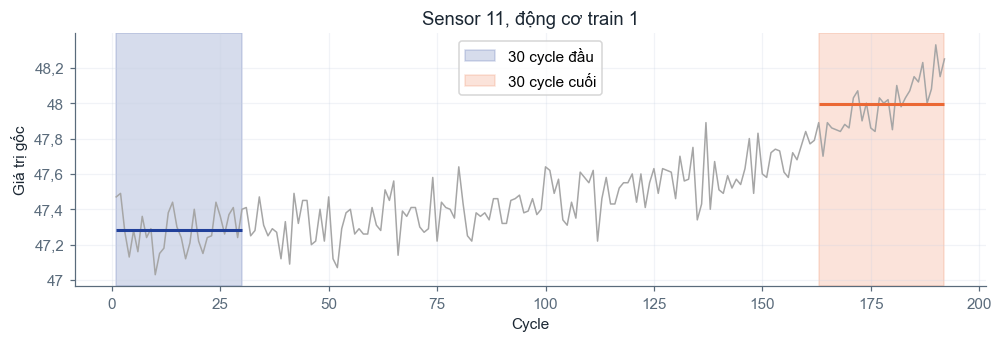

In [3]:
fig, ax = plt.subplots(figsize=(9, 3), layout="constrained")
ax.plot(engine1.cycle, engine1.sensor_11, color="0.65", linewidth=1)
ax.axvspan(1, 30, alpha=0.18, color=COLORS["blue"], label="30 cycle đầu")
ax.axvspan(163, 192, alpha=0.18, color=COLORS["orange"], label="30 cycle cuối")
ax.hlines(early.mean(), 1, 30, color=COLORS["blue"], linewidth=2)
ax.hlines(late.mean(), 163, 192, color=COLORS["orange"], linewidth=2)
ax.set(title="Sensor 11, động cơ train 1", xlabel="Cycle", ylabel="Giá trị gốc")
ax.legend()
style_figure(plt.gcf())
plt.show()

## 2. Một sensor, 100 động cơ, 100 giá trị Δ

Cycle liền kề trong cùng động cơ có phụ thuộc theo thời gian. Vì vậy, đơn vị phân tích ở đây là động cơ.
Hàm của project tạo 100 chênh lệch cho mỗi sensor, tổng cộng 2.100 cặp (động cơ, sensor).
Bảng nhỏ dưới đây giữ sensor 11 để kiểm tra công thức trước khi kiểm định.

In [4]:
from cmapss.statistics import build_engine_sensor_pairs

pairs = build_engine_sensor_pairs(train)
example = pairs.query("engine_id == 1 and sensor == 'sensor_11'").iloc[0]
assert np.isclose(example.difference, difference)
pairs.query("sensor == 'sensor_11'")[
    ["engine_id", "early_mean", "late_mean", "difference"]
].head(5)

,engine_id,early_mean,late_mean,difference
10,1,47.282667,47.995333,0.712667
31,2,47.139333,48.013667,0.874333
52,3,47.224667,47.853000,0.628333
73,4,47.388667,47.899667,0.511000
94,5,47.154000,47.985000,0.831000


## 3. Khoảng tin cậy và kiểm định trả lời điều gì?

Bootstrap lấy mẫu lại **100 động cơ có hoàn lại**, 10.000 lần, để ước lượng khoảng tin cậy 95%
của trung bình Δ. Wilcoxon signed-rank kiểm tra vị trí của phân phối chênh lệch quanh 0;
cách diễn giải theo trung vị cần giả định phân phối chênh lệch đối xứng.

P-value dùng 100.000 hoán vị. Hiệu chỉnh Benjamini–Hochberg (BH) xét cả 21 sensor,
với FDR (tỷ lệ phát hiện sai kỳ vọng) ở mức 5%. FDR không phải xác suất một kết luận cụ thể bị sai.
Seed 42 giữ phép lấy mẫu có thể tái lập.

In [5]:
from cmapss.statistics import SensorInferenceConfig

config = SensorInferenceConfig()
pd.Series({
    "bootstrap_resamples": config.bootstrap_resamples,
    "permutation_resamples": config.wilcoxon_permutation_resamples,
    "confidence_level": config.bootstrap_confidence_level,
    "FDR_q": config.fdr_q, "family_size": config.fdr_family_size, "seed": config.seed,
})

bootstrap_resamples       10000.00
permutation_resamples    100000.00
confidence_level              0.95
FDR_q                         0.05
family_size                  21.00
seed                         42.00
dtype: float64

Chạy pipeline với cấu hình trên và ghi vào thư mục riêng. Pipeline cũng kiểm tra
bảng sau khi ghi/đọc lại và xác nhận raw không đổi.

In [6]:
import os
import tempfile
from cmapss.statistics_artifacts import write_sensor_statistics_artifacts

output_root = ROOT / "outputs/notebook02"
output_root.mkdir(parents=True, exist_ok=True)
requested_output = os.environ.get("CMAPSS_STATISTICS_NOTEBOOK_OUTPUT")
OUTPUT = Path(requested_output) if requested_output else Path(tempfile.mkdtemp(prefix="run-", dir=output_root))
result = write_sensor_statistics_artifacts(
    project_root=ROOT, raw_dir="data/raw", output_dir=OUTPUT, config=config,
)
pd.testing.assert_frame_equal(pairs, result.pairs)
inference = result.inference
inference[["sensor", "mean_difference", "ci_lower", "ci_upper", "p_value_adjusted", "test_status"]]

,sensor,mean_difference,ci_lower,ci_upper,p_value_adjusted,test_status
0,sensor_1,0.000000,0.000000,0.000000,NaN,all_zero_difference
1,sensor_2,0.999310,0.959059,1.040183,0.000028,ok
2,sensor_3,11.908667,11.443951,12.377164,0.000028,ok
3,sensor_4,20.128097,19.402735,20.865606,0.000028,ok
4,sensor_5,0.000000,0.000000,0.000000,NaN,all_zero_difference
5,sensor_6,0.000447,0.000320,0.000580,0.000028,ok
6,sensor_7,-1.913527,-1.999307,-1.829684,0.000028,ok
7,sensor_8,0.130297,0.119533,0.141294,0.000028,ok
8,sensor_9,31.531620,24.236336,39.319072,0.000028,ok
9,sensor_10,0.000000,0.000000,0.000000,NaN,all_zero_difference


Sáu sensor 1, 5, 10, 16, 18, 19 có Δ = 0 ở mọi động cơ, nên không kiểm định.
Với 15 sensor còn lại, p-value sau BH đều khoảng 0,000028. P-value thô khoảng 0,00002
gần mức nhỏ nhất có thể đạt với 100.000 hoán vị; không dùng nó để xếp hạng độ lớn thay đổi.

Ví dụ, sensor 4 tăng khoảng 20,13 còn sensor 7 giảm khoảng 1,91. Đơn vị khác nhau nên hai độ lớn
không so sánh trực tiếp. Cần đọc cả chiều, độ lớn và mức khác nhau giữa các động cơ.

## 4. Cùng có ý nghĩa thống kê nhưng khác cách thay đổi

Sensor 11 minh họa thay đổi khá nhất quán. Sensor 9 và 14 có động cơ tăng, có động cơ giảm.
Sensor 6 minh họa mức thay đổi rất nhỏ dù p-value nhỏ. Xem số dấu trước, rồi xem phân phối Δ.

In [7]:
chosen = ["sensor_11", "sensor_9", "sensor_14", "sensor_6"]
inference.set_index("sensor").loc[
    chosen, ["n_positive", "n_negative", "n_zero", "mean_difference", "median_difference"]
]

,n_positive,n_negative,n_zero,mean_difference,median_difference
sensor,,,,,
sensor_11,100,0,0,0.613257,0.595000
sensor_9,71,29,0,31.531620,17.630333
sensor_14,58,42,0,22.056027,9.499500
sensor_6,47,0,53,0.000447,0.000000


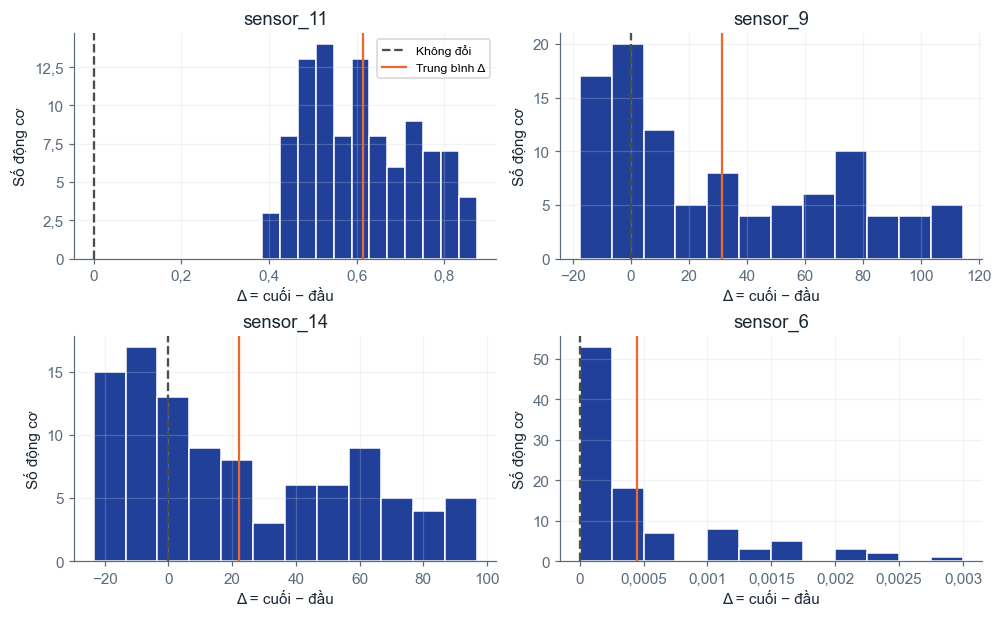

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5.5), layout="constrained")
for ax, sensor in zip(axes.flat, chosen):
    values = pairs.loc[pairs.sensor.eq(sensor), "difference"]
    ax.hist(values, bins=12, color=COLORS["blue"], edgecolor="white")
    ax.axvline(0, color="0.3", linestyle="--", label="Không đổi")
    ax.axvline(values.mean(), color=COLORS["orange"], label="Trung bình Δ")
    ax.set(title=sensor, xlabel="Δ = cuối − đầu", ylabel="Số động cơ")
axes[0, 0].legend(fontsize=8)
(OUTPUT / "figures").mkdir()
style_figure(fig)
fig.savefig(OUTPUT / "figures/difference_distributions.png", dpi=150)
style_figure(plt.gcf())
plt.show()

Với phần lớn sensor, cả 100 giá trị Δ cùng nằm về một phía của 0, tức các động cơ biến đổi cùng chiều.
Hai ngoại lệ là `sensor_9` với 71 động cơ tăng, 29 giảm và `sensor_14` với 58 tăng, 42 giảm.
Trung bình Δ của `sensor_9` và `sensor_14` (31,5 và 22,1) cao hơn median (17,6 và 9,5) do một nhóm động cơ tăng rất mạnh.
Động cơ 26 trong phần EDA là một ví dụ.

Sensor 6 có 47 động cơ tăng và 53 động cơ không đổi; trung bình Δ chỉ 0,00045.
P-value nhỏ cho biết bằng chứng về thay đổi, không cho biết thay đổi có đủ lớn để hữu ích trong dự đoán.

Hình tiếp theo biểu diễn trung bình Δ và khoảng tin cậy 95% của bốn sensor này.
Mỗi ô có thang riêng. Đường gạch tại 0 giúp xác định khoảng có đi qua mốc không thay đổi không.

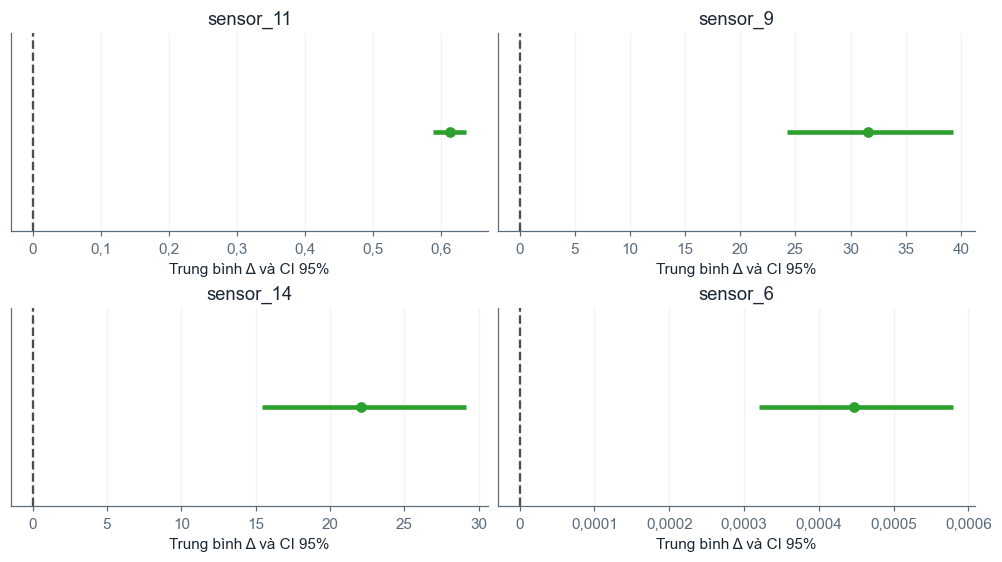

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5), layout="constrained")
for ax, sensor in zip(axes.flat, chosen):
    row = inference.set_index("sensor").loc[sensor]
    ax.hlines(0, row.ci_lower, row.ci_upper, color="tab:green", linewidth=3)
    ax.scatter(row.mean_difference, 0, color="tab:green", zorder=3)
    ax.axvline(0, color="0.3", linestyle="--")
    ax.set(title=sensor, xlabel="Trung bình Δ và CI 95%", yticks=[])
style_figure(fig)
fig.savefig(OUTPUT / "figures/effect_size_ci.png", dpi=150)
style_figure(plt.gcf())
plt.show()

Khoảng tin cậy 95% của 15 sensor được kiểm định đều nằm về một phía của 0.
`sensor_9` có khoảng 24,2 đến 39,3; `sensor_14` từ 15,5 đến 29,2. Hai khoảng này rộng nhất so với
trung bình Δ, thể hiện sự khác nhau giữa các động cơ. Các sensor khác có khoảng hẹp hơn,
chẳng hạn `sensor_11` từ 0,589 đến 0,638.

## 5. Từ kết quả kiểm định đến giới hạn kết luận

Bảng cuối giữ đủ 21 sensor để đối chiếu. `fdr_reject` là quyết định sau hiệu chỉnh BH;
`all_zero_difference` là trường hợp không kiểm định vì mọi chênh lệch bằng 0.

In [10]:
inference[["sensor", "n_positive", "n_negative", "n_zero", "fdr_reject", "test_status"]]

,sensor,n_positive,n_negative,n_zero,fdr_reject,test_status
0,sensor_1,0,0,100,<NA>,all_zero_difference
1,sensor_2,100,0,0,True,ok
2,sensor_3,100,0,0,True,ok
3,sensor_4,100,0,0,True,ok
4,sensor_5,0,0,100,<NA>,all_zero_difference
5,sensor_6,47,0,53,True,ok
6,sensor_7,0,100,0,True,ok
7,sensor_8,100,0,0,True,ok
8,sensor_9,71,29,0,True,ok
9,sensor_10,0,0,100,<NA>,all_zero_difference


In [11]:
assert len(pairs) == 2100 and len(inference) == 21
assert inference.fdr_reject.sum() == 15
print(f"Kết quả lần chạy: {OUTPUT.relative_to(ROOT)}")

Kết quả lần chạy: outputs\notebook02\run-22nphh5o


Mười lăm sensor thay đổi rõ giữa hai đoạn đầu/cuối của 100 động cơ train; sáu sensor còn lại không đổi.
Phép kiểm tra này không đánh giá khả năng dự đoán trên động cơ mới.

Mô hình chính ở notebook 03 vẫn dùng đủ 126 features cửa sổ từ 21 sensor. Nếu thử chọn sensor theo
kiểm định, việc chọn chỉ được dùng dữ liệu của training fold. Không dùng kết quả trên toàn bộ train
để chọn features rồi đánh giá lại trên chính các động cơ ấy.